NAMA : NABILA KIRANA AINUN

NIM : H061241030

---
### PROMPT PENYELESAIAN STUDI KASUS GEOFISIKA MENGGUNAKAN METODE ELECTRICAL RESISTIVITY TOMOGRAPHY (ERT)

ROLE (R): 

Kamu adalah seorang ahli geofisika yang berpengalaman dalam interpretasi data geolistrik, khususnya metode ERT (Electrical Resistivity Tomography), untuk keperluan eksplorasi bawah permukaan (misalnya deteksi lapisan akuifer, struktur geologi, atau zona anomali resistivitas).

TASK (T):

Selesaikan studi kasus interpretasi data ERT berikut ini: analisis pola distribusi nilai resistivitas bawah permukaan, identifikasi kemungkinan jenis litologi/material pada tiap lapisan, dan simpulkan kondisi geologi bawah permukaan berdasarkan data yang diberikan.

CONTEXT (C):

Data ERT diperoleh dari survei geolistrik konfigurasi [sebutkan: Wenner/Schlumberger/Dipole-Dipole] dengan panjang lintasan [isi], jumlah elektroda [isi], dan spasi elektroda [isi]. Lokasi survei berada di [isi lokasi/tujuan survei, misalnya pencarian akuifer, deteksi bidang gelincir longsor, dsb].

INPUT (I):

1. Nilai resistivitas semu (apparent resistivity) hasil pengukuran lapangan
2. Hasil inversi 2D/3D (jika ada, dalam bentuk deskripsi rentang nilai resistivitas per kedalaman)
3. Informasi geologi regional/pendukung (jika tersedia)

CONSTRAINTS (K):

1. Interpretasi harus didasarkan pada nilai resistivitas yang wajar sesuai referensi geologi umum (misalnya lempung: rendah, pasir/kerikil kering: tinggi, air tanah: sedang-rendah, batuan dasar: tinggi)
2. Tidak diperbolehkan membuat asumsi litologi tanpa mengaitkannya dengan rentang nilai resistivitas yang diberikan
3. Jangan sertakan perhitungan matematis, rumus inversi, atau kode pemrograman

OUTPUT (O):

Sampaikan hasil interpretasi hanya dalam bentuk narasi (bukan tabel, grafik, atau poin-poin terpisah), yang menjelaskan secara mengalir:

1. Gambaran umum pola resistivitas yang teramati
2. Identifikasi lapisan-lapisan bawah permukaan beserta kemungkinan material/litologinya
3. Interpretasi kondisi geologi keseluruhan berdasarkan pola tersebut
4. Kesimpulan yang relevan dengan tujuan survei

## Eksekusi 1: Electrical Resistivity Tomography (ERT)

**Data sintetis:** penampang resistivitas 2D hasil survei Wenner-Schlumberger dengan 48 elektroda, spasi 2 m (panjang lintasan 94 m, kedalaman model 20 m). Tujuan survei: mencari lapisan akuifer. Model berisi tanah penutup kering, lapisan lempung, lapisan pasir-kerikil jenuh air, batuan dasar yang menaik di sekitar jarak 30 m, dan satu zona lemah di sekitar jarak 70 m. Data dibuat untuk demonstrasi, bukan hasil survei lapangan.

**Tujuan eksekusi:** menampilkan pola resistivitas lateral dan vertikal, lalu mengaitkan rentang nilainya dengan kemungkinan litologi.

ERT - DATA SINTETIS (Wenner-Schlumberger, 48 elektroda, spasi 2 m, panjang 94 m)
Rentang resistivitas model : 23.1-660.3 ohm.m

A. Penutup permukaan               median  248.4 ohm.m  (P5-P95: 236-260)
B. Lapisan konduktif (lempung)     median   25.0 ohm.m  (P5-P95: 24-26)
C. Lapisan jenuh air (akuifer?)    median   89.9 ohm.m  (P5-P95: 81-100)
D. Batuan dasar                    median  594.7 ohm.m  (P5-P95: 480-627)
E. Zona lemah (x = 66-74 m)        median   64.8 ohm.m  (P5-P95: 54-68)
Catatan: nilai dibuat untuk demonstrasi, bukan hasil inversi lapangan.


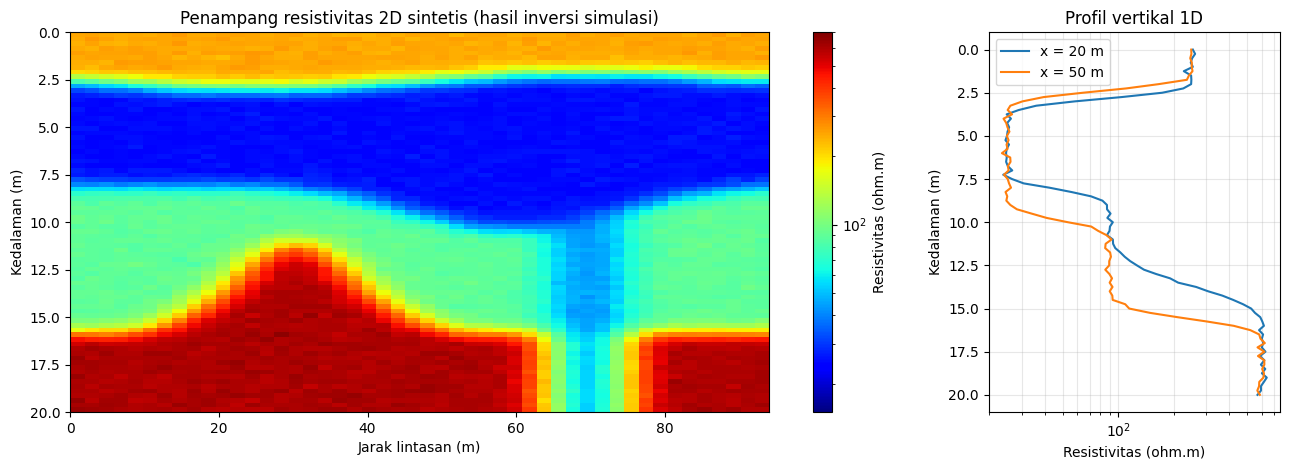

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter

# ============================================================
# 1. PARAMETER SURVEI (SINTETIS)
# ============================================================
# Konfigurasi Wenner-Schlumberger, 48 elektroda, spasi 2 m -> panjang lintasan 94 m
n_elektroda, spasi = 48, 2.0
x = np.arange(n_elektroda) * spasi              # posisi elektroda (m)
z = np.linspace(0, 20, 81)                      # kedalaman model (m)
X, Z = np.meshgrid(x, z)

# ============================================================
# 2. MODEL RESISTIVITAS SINTETIS (hasil inversi 2D yang disimulasikan)
# ============================================================
z1 = 2.5 + 0.4*np.sin(X/15)                      # dasar lapisan tanah penutup kering
z2 = 8.0 + 2.5*np.exp(-((X-60)/20)**2)           # dasar lapisan lempung
z3 = 16.0 - 5.0*np.exp(-((X-30)/12)**2)          # puncak batuan dasar (menaik di sekitar x = 30 m)

rho = np.where(Z < z1, 250.0,                    # tanah/pasir kerikilan kering
      np.where(Z < z2, 25.0,                     # lempung
      np.where(Z < z3, 90.0, 600.0)))            # pasir-kerikil jenuh air | batuan dasar
fault = (X >= 66) & (X <= 74) & (Z >= z3 - 6)    # zona lemah (retakan terisi air) memotong lapisan dalam
rho[fault] = 40.0

# Efek penghalusan inversi dan noise 3 %
rng = np.random.default_rng(7)
rho = gaussian_filter(np.log(rho), sigma=1.6)
rho = np.exp(rho + 0.03*rng.normal(size=rho.shape))

# ============================================================
# 3. RINGKASAN NILAI RESISTIVITAS PER ZONA
# ============================================================
zona = {
    "A. Penutup permukaan"            : (Z < z1-0.8),
    "B. Lapisan konduktif (lempung)"  : (Z > z1+1.0) & (Z < z2-1.0),
    "C. Lapisan jenuh air (akuifer?)" : (Z > z2+1.0) & (Z < z3-1.0) & ~((X>62)&(X<78)),
    "D. Batuan dasar"                 : (Z > z3+1.0) & ~((X>62)&(X<78)),
    "E. Zona lemah (x = 66-74 m)"     : fault & (Z > z3+1.5) & (X>67.5) & (X<72.5),
}
print("ERT - DATA SINTETIS (Wenner-Schlumberger, 48 elektroda, spasi 2 m, panjang 94 m)")
print(f"Rentang resistivitas model : {rho.min():.1f}-{rho.max():.1f} ohm.m\n")
for nama, m in zona.items():
    p5, p50, p95 = np.percentile(rho[m], [5, 50, 95])
    print(f"{nama:34s} median {p50:6.1f} ohm.m  (P5-P95: {p5:.0f}-{p95:.0f})")
print("Catatan: nilai dibuat untuk demonstrasi, bukan hasil inversi lapangan.")

# ============================================================
# 4. VISUALISASI
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 1]})
im = ax[0].imshow(rho, extent=[x.min(), x.max(), z.max(), z.min()], aspect="auto",
                  cmap="jet", norm=LogNorm(vmin=15, vmax=700))
fig.colorbar(im, ax=ax[0], label="Resistivitas (ohm.m)")
ax[0].set_xlabel("Jarak lintasan (m)"); ax[0].set_ylabel("Kedalaman (m)")
ax[0].set_title("Penampang resistivitas 2D sintetis (hasil inversi simulasi)")

profil = rho[:, np.argmin(abs(x-20))], rho[:, np.argmin(abs(x-50))]
ax[1].semilogx(profil[0], z, label="x = 20 m")
ax[1].semilogx(profil[1], z, label="x = 50 m")
ax[1].invert_yaxis(); ax[1].grid(True, which="both", alpha=0.3)
ax[1].set_xlabel("Resistivitas (ohm.m)"); ax[1].set_ylabel("Kedalaman (m)")
ax[1].set_title("Profil vertikal 1D"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretasi hasil:** Penampang resistivitas sintetis memperlihatkan susunan berlapis yang nilainya berubah tajam terhadap kedalaman, dengan perubahan lateral yang jelas di sekitar jarak 30 m dan 70 m. Pada bagian paling atas, hingga kedalaman sekitar 2 sampai 3 m, terdapat zona beresistivitas tinggi sekitar 250 ohm.m. Nilai setinggi ini sesuai dengan tanah penutup berpasir atau kerikilan yang kering dan belum jenuh air. Tepat di bawahnya terdapat lapisan konduktif dengan resistivitas sekitar 25 ohm.m yang menerus di seluruh lintasan hingga kedalaman 8 sampai 10 m dan tampak menebal di sekitar jarak 60 m. Resistivitas serendah ini lazim untuk lempung atau material halus yang jenuh air, sehingga lapisan ini lebih tepat dibaca sebagai lapisan penyekat daripada sebagai akuifer yang produktif.

Di bawah lapisan lempung, resistivitas naik menjadi sekitar 90 ohm.m (kisaran 80 sampai 100 ohm.m) pada kedalaman kurang lebih 8 sampai 16 m. Nilai sedang ini sejalan dengan pasir atau kerikil yang jenuh air, sehingga zona tersebut menjadi kandidat utama akuifer. Perlu diingat bahwa nilai yang sama juga dapat berasal dari pasir lempungan dengan kandungan air berbeda, sehingga dugaan akuifer ini perlu dikonfirmasi dengan data bor. Bagian terdalam penampang bernilai sekitar 600 ohm.m, yang sesuai dengan batuan dasar yang kompak dan relatif kering. Puncak batuan dasar tampak naik hingga kedalaman sekitar 11 m di sekitar jarak 30 m, sehingga lapisan akuifer menipis di bagian itu dan lebih tebal di bagian lain lintasan. Di sekitar jarak 66 sampai 74 m terlihat zona sempit beresistivitas sekitar 65 ohm.m yang memotong batuan dasar. Pola ini dapat menunjukkan zona retakan atau patahan yang terisi air atau material hasil pelapukan, tetapi jenis pengisinya tidak dapat dipastikan hanya dari resistivitas.

Secara keseluruhan, kondisi bawah permukaan yang ditafsirkan adalah tanah penutup kering di atas lempung, lalu pasir-kerikil jenuh air, dan batuan dasar di bagian paling bawah. Terkait tujuan survei, lokasi yang paling menjanjikan untuk pemboran air tanah berada di bagian lintasan dengan lapisan beresistivitas sekitar 90 ohm.m yang tebal, yaitu di luar area naiknya batuan dasar di sekitar jarak 30 m. Zona lemah di sekitar jarak 70 m dapat menjadi target tambahan, namun perlu diverifikasi karena nilai resistivitas tidak bersifat unik.

---

### PROMPT PENYELESAIAN STUDI KASUS GEOFISIKA MENGGUNAKAN METODE THEODOLITE

Role (R)

Anda adalah seorang ahli geofisika dan survei yang berpengalaman dalam penggunaan theodolite untuk pengukuran sudut horizontal dan vertikal, penentuan posisi stasiun, pemetaan topografi pendukung akuisisi data geofisika, serta penyusunan laporan teknis yang jelas dan sistematis.

Task (T)

Selesaikan studi kasus geofisika yang melibatkan metode theodolite. Lakukan analisis lengkap mulai dari pemahaman data pengukuran sudut dan posisi, pengolahan koordinat, interpretasi hasil survei, hingga penarikan kesimpulan, kemudian sampaikan seluruh hasilnya hanya dalam bentuk narasi.

Context (C)

Studi kasus ini menggunakan theodolite sebagai instrumen utama untuk memperoleh data sudut, posisi, dan elevasi yang mendukung analisis struktur atau kondisi lapangan dalam konteks geofisika. Hasil akhir harus dapat dipahami oleh pembaca teknis maupun semi-teknis tanpa menyajikan tabel, grafik, atau format terstruktur lainnya.

Input (I)

[Sisipkan di sini data atau deskripsi studi kasus yang Anda miliki, misalnya: data pembacaan sudut horizontal dan vertikal, jarak, koordinat stasiun, atau hasil perhitungan posisi. Jika belum tersedia, tuliskan “Data studi kasus akan diberikan kemudian.”]

Constraints (K)

1. Gunakan hanya metode theodolite sebagai instrumen utama.
2. Jangan menyajikan output dalam bentuk tabel, daftar bernomor, bullet point, persamaan matematis terpisah, atau diagram.
3. Seluruh penjelasan harus mengalir dalam bentuk paragraf naratif yang koheren.
4. Fokus pada proses analisis, interpretasi hasil pengukuran, dan kesimpulan praktis dalam konteks geofisika.
5. Hindari spekulasi di luar data yang diberikan.

Output (O)

Sampaikan hasil penyelesaian studi kasus sepenuhnya dalam bentuk narasi mengalir. Narasi harus mencakup: ringkasan pendekatan yang digunakan, langkah-langkah analisis yang dilakukan, interpretasi hasil pengukuran sudut dan posisi yang diperoleh, serta kesimpulan dan implikasi praktis dari hasil tersebut. Tidak boleh ada format lain selain paragraf naratif.

## Eksekusi 2: Theodolite

**Data sintetis:** poligon tertutup dengan 5 stasiun (A-B-C-D-E) yang diukur dengan theodolite. Data berupa sudut horizontal dalam, jarak, dan sudut vertikal di tiap stasiun, yang dibangkitkan dengan kesalahan acak kecil. Poligon ini diasumsikan sebagai kerangka titik kontrol untuk mendukung lintasan akuisisi data geofisika. Data dibuat untuk demonstrasi, bukan hasil pengukuran lapangan.

**Tujuan eksekusi:** menghitung koreksi sudut, azimuth, koordinat, koreksi Bowditch, dan elevasi stasiun, lalu menilai kualitas pengukuran dari salah penutupnya.

THEODOLITE - DATA SINTETIS (poligon tertutup 5 stasiun)
Keliling poligon              : 358.75 m
Salah penutup sudut           : -11.2 detik busur -> koreksi +2.2 detik/sudut
Salah penutup linier          : dE = +0.4 cm, dN = -5.3 cm, total 5.3 cm
Ketelitian linier (presisi)   : 1 : 6,720
Salah penutup beda tinggi     : -0.8 cm

Stasiun   E (m)      N (m)     H (m)   | selisih thd nilai benar (cm)
   A      1000.00    5000.00   25.00   |  dE  +0.0  dN  +0.0  dH  +0.0
   B      1080.00    5010.01   26.40   |  dE  -0.3  dN  +1.2  dH  +0.3
   C      1109.98    5070.01   28.10   |  dE  -2.0  dN  +0.7  dH  +0.2
   D      1049.98    5110.01   27.20   |  dE  -2.2  dN  +1.1  dH  +0.3
   E       989.99    5060.02   25.90   |  dE  -1.1  dN  +2.3  dH  +0.2
Catatan: data ukur dibangkitkan secara simulasi, bukan pengukuran lapangan.


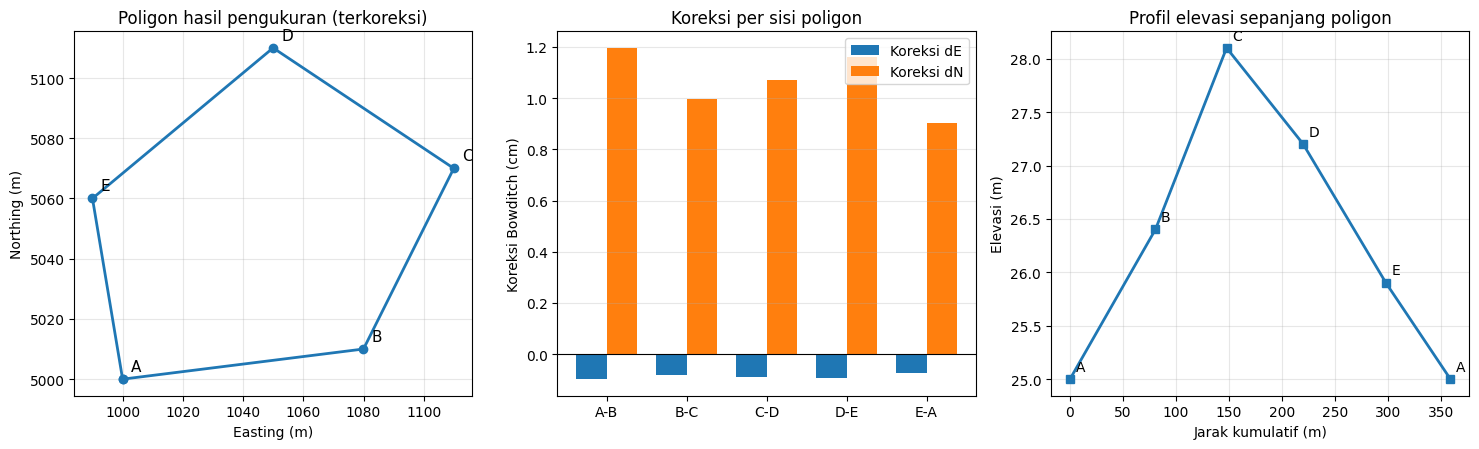

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. DATA SINTETIS: POLIGON TERTUTUP 5 STASIUN (A-B-C-D-E-A)
# ============================================================
stasiun = ["A", "B", "C", "D", "E"]
E_true = np.array([1000.0, 1080.0, 1110.0, 1050.0,  990.0])
N_true = np.array([5000.0, 5010.0, 5070.0, 5110.0, 5060.0])
H_true = np.array([  25.00,  26.40,  28.10,  27.20,  25.90])
n = len(stasiun)
rng = np.random.default_rng(3)

# Nilai "benar" -> dipakai hanya untuk membangkitkan data ukur sintetis
nxt = (np.arange(n)+1) % n
dE, dN = E_true[nxt]-E_true, N_true[nxt]-N_true
az_true = np.degrees(np.arctan2(dE, dN)) % 360          # azimuth sisi i -> i+1
D_true  = np.hypot(dE, dN)
sudut_true = (az_true - np.roll(az_true, 1) + 180) % 360  # sudut dalam di tiap stasiun

# Data "pengukuran": sudut horizontal (+-10"), jarak (+-1 cm), sudut vertikal (+-10")
sudut_ukur = sudut_true + rng.normal(0, 10, n)/3600
D_ukur     = D_true + rng.normal(0, 0.01, n)
hi, ht = 1.52, 1.60                                      # tinggi alat dan tinggi target (m)
dH_true = H_true[nxt] - H_true
alpha_ukur = np.degrees(np.arctan((dH_true - hi + ht)/D_true)) + rng.normal(0, 10, n)/3600

# ============================================================
# 2. KOREKSI SUDUT (syarat geometri poligon)
# ============================================================
salah_sudut = sudut_ukur.sum() - (n-2)*180
sudut_adj = sudut_ukur - salah_sudut/n

# ============================================================
# 3. AZIMUTH, SELISIH KOORDINAT, DAN KOREKSI BOWDITCH
# ============================================================
az = np.zeros(n); az[0] = az_true[0]                     # azimuth awal A->B diketahui (orientasi)
for i in range(1, n):
    az[i] = (az[i-1] + sudut_adj[i] - 180) % 360         # poligon berlawanan arah jarum jam

dE_m = D_ukur*np.sin(np.radians(az)); dN_m = D_ukur*np.cos(np.radians(az))
eE, eN = dE_m.sum(), dN_m.sum()
salah_linier = np.hypot(eE, eN)
presisi = D_ukur.sum()/salah_linier

dE_adj = dE_m - eE*D_ukur/D_ukur.sum()                   # Bowditch
dN_adj = dN_m - eN*D_ukur/D_ukur.sum()
E_adj = E_true[0] + np.r_[0, np.cumsum(dE_adj)[:-1]]
N_adj = N_true[0] + np.r_[0, np.cumsum(dN_adj)[:-1]]

# ============================================================
# 4. BEDA TINGGI (TRIGONOMETRIK) DAN PEMERATAAN
# ============================================================
dH_m = D_ukur*np.tan(np.radians(alpha_ukur)) + hi - ht
salah_tinggi = dH_m.sum()
dH_adj = dH_m - salah_tinggi*D_ukur/D_ukur.sum()
H_adj = H_true[0] + np.r_[0, np.cumsum(dH_adj)[:-1]]

# ============================================================
# 5. HASIL
# ============================================================
print("THEODOLITE - DATA SINTETIS (poligon tertutup 5 stasiun)")
print(f"Keliling poligon              : {D_ukur.sum():.2f} m")
print(f"Salah penutup sudut           : {salah_sudut*3600:+.1f} detik busur -> koreksi {-salah_sudut*3600/n:+.1f} detik/sudut")
print(f"Salah penutup linier          : dE = {eE*100:+.1f} cm, dN = {eN*100:+.1f} cm, total {salah_linier*100:.1f} cm")
print(f"Ketelitian linier (presisi)   : 1 : {presisi:,.0f}")
print(f"Salah penutup beda tinggi     : {salah_tinggi*100:+.1f} cm\n")
print("Stasiun   E (m)      N (m)     H (m)   | selisih thd nilai benar (cm)")
for i, s in enumerate(stasiun):
    print(f"   {s}    {E_adj[i]:9.2f}  {N_adj[i]:9.2f}  {H_adj[i]:6.2f}   |  "
          f"dE {100*(E_adj[i]-E_true[i]):+5.1f}  dN {100*(N_adj[i]-N_true[i]):+5.1f}  dH {100*(H_adj[i]-H_true[i]):+5.1f}")
print("Catatan: data ukur dibangkitkan secara simulasi, bukan pengukuran lapangan.")

# ============================================================
# 6. VISUALISASI
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
tutup = lambda a: np.r_[a, a[0]]
ax[0].plot(tutup(E_adj), tutup(N_adj), "-o", lw=2)
for i, s in enumerate(stasiun):
    ax[0].annotate(s, (E_adj[i], N_adj[i]), textcoords="offset points", xytext=(6, 6), fontsize=11)
ax[0].set_aspect("equal"); ax[0].grid(True, alpha=0.3)
ax[0].set_xlabel("Easting (m)"); ax[0].set_ylabel("Northing (m)"); ax[0].set_title("Poligon hasil pengukuran (terkoreksi)")

idx = np.arange(n); w = 0.38
ax[1].bar(idx-w/2, -eE*D_ukur/D_ukur.sum()*100, w, label="Koreksi dE")
ax[1].bar(idx+w/2, -eN*D_ukur/D_ukur.sum()*100, w, label="Koreksi dN")
ax[1].set_xticks(idx); ax[1].set_xticklabels([f"{stasiun[i]}-{stasiun[nxt[i]]}" for i in idx])
ax[1].axhline(0, color="k", lw=0.8); ax[1].grid(True, axis="y", alpha=0.3)
ax[1].set_ylabel("Koreksi Bowditch (cm)"); ax[1].set_title("Koreksi per sisi poligon"); ax[1].legend()

jarak = np.r_[0, np.cumsum(D_ukur)]; H_plot = np.r_[H_adj, H_adj[0]]
ax[2].plot(jarak, H_plot, "-s", lw=2)
for i, s in enumerate(stasiun + ["A"]):
    ax[2].annotate(s, (jarak[i], H_plot[i]), textcoords="offset points", xytext=(4, 6))
ax[2].grid(True, alpha=0.3); ax[2].set_xlabel("Jarak kumulatif (m)"); ax[2].set_ylabel("Elevasi (m)")
ax[2].set_title("Profil elevasi sepanjang poligon")
plt.tight_layout(); plt.show()

**Interpretasi hasil:** Pengukuran poligon tertutup lima stasiun dengan keliling sekitar 358,75 m menghasilkan salah penutup sudut sebesar sekitar minus 11,2 detik busur. Nilai ini sangat kecil untuk lima sudut, sehingga dapat dibagi rata sebagai koreksi sekitar 2,2 detik pada setiap sudut tanpa mengubah geometri poligon secara berarti. Setelah azimuth dihitung dari sudut terkoreksi, selisih koordinat tiap sisi menghasilkan salah penutup linier sekitar 5,3 cm, hampir seluruhnya pada arah utara-selatan. Dibandingkan dengan keliling poligon, angka ini setara dengan ketelitian sekitar 1 banding 6.700. Ketelitian tersebut tergolong baik untuk pengukuran poligon yang berfungsi sebagai kontrol lapangan, sehingga koreksi Bowditch yang membagi salah penutup sebanding dengan panjang sisi dapat diterapkan. Koreksi per sisi hanya beberapa sentimeter dan tidak mengubah bentuk poligon.

Pada sisi elevasi, pembacaan sudut vertikal yang dikombinasikan dengan jarak, tinggi alat, dan tinggi target menghasilkan salah penutup beda tinggi sekitar minus 0,8 cm. Angka ini cukup kecil untuk diratakan secara proporsional terhadap jarak. Elevasi akhir stasiun berturut-turut adalah sekitar 25,00 m di A, 26,40 m di B, 28,10 m di C, 27,20 m di D, dan 25,90 m di E. Stasiun C menjadi titik tertinggi dengan selisih sekitar 3,1 m terhadap titik awal A, sedangkan elevasi menurun kembali ke arah D dan E. Karena data dibangkitkan secara simulasi, koordinat terkoreksi dapat dibandingkan dengan nilai sebenarnya, dan perbedaannya tercatat tidak lebih dari beberapa sentimeter. Dalam pengukuran nyata, perbandingan seperti ini tidak tersedia sehingga penilaian kualitas hanya bertumpu pada salah penutup.

Secara praktis, hasil ini menunjukkan bahwa kerangka titik kontrol sudah memadai untuk menentukan posisi horizontal dan elevasi stasiun yang mendukung akuisisi geofisika, misalnya untuk menempatkan lintasan atau melakukan koreksi topografi. Interpretasi ini terbatas pada kualitas geometri pengukuran dan tidak dapat digunakan untuk menyimpulkan kondisi geologi bawah permukaan.

---

### PROMPT PENYELESAIAN STUDI KASUS GEOFISIKA MENGGUNAKAN METODE MASW

Role (R)

Anda adalah seorang ahli geofisika dengan spesialisasi metode Multichannel Analysis of Surface Waves (MASW), berpengalaman dalam akuisisi dan pengolahan data gelombang permukaan, analisis dispersi, inversi profil kecepatan gelombang geser (Vs), serta penyusunan laporan teknis yang jelas dan sistematis.

Task (T)

Selesaikan studi kasus geofisika menggunakan metode MASW. Lakukan analisis lengkap mulai dari pemahaman data, pengolahan kurva dispersi, interpretasi profil kecepatan gelombang geser, hingga penarikan kesimpulan, kemudian sampaikan seluruh hasilnya hanya dalam bentuk narasi.

Context (C)

Studi kasus ini menggunakan metode Multichannel Analysis of Surface Waves untuk memperoleh informasi struktur bawah permukaan dangkal berdasarkan distribusi kecepatan gelombang geser (Vs). Hasil akhir harus dapat dipahami oleh pembaca teknis maupun semi-teknis tanpa menyajikan tabel, grafik, atau format terstruktur lainnya.

Input (I)

[Sisipkan di sini data atau deskripsi studi kasus yang Anda miliki, misalnya: data rekaman gelombang permukaan, kurva dispersi, parameter akuisisi, atau hasil inversi profil Vs. Jika belum tersedia, tuliskan “Data studi kasus akan diberikan kemudian.”]

Constraints (K)

1. Gunakan hanya metode MASW.
2. Jangan menyajikan output dalam bentuk tabel, daftar bernomor, bullet point, persamaan matematis terpisah, atau diagram.
3. Seluruh penjelasan harus mengalir dalam bentuk paragraf naratif yang koheren.
4. Fokus pada proses analisis, interpretasi geologi/geofisika, dan kesimpulan praktis.
5. Hindari spekulasi di luar data yang diberikan.

Output (O)

Sampaikan hasil penyelesaian studi kasus sepenuhnya dalam bentuk narasi mengalir. Narasi harus mencakup: ringkasan pendekatan yang digunakan, langkah-langkah analisis yang dilakukan, interpretasi struktur bawah permukaan yang diperoleh dari profil kecepatan gelombang geser, serta kesimpulan dan implikasi praktis dari hasil tersebut. Tidak boleh ada format lain selain paragraf naratif.

## Eksekusi 3: Multichannel Analysis of Surface Waves (MASW)

**Data sintetis:** rekaman gelombang permukaan dengan 24 geophone, spasi 2 m, dan offset awal 5 m. Rekaman dibangkitkan dari kurva dispersi yang kecepatan fasenya menurun terhadap frekuensi, ditambah noise acak. Data dibuat untuk demonstrasi, bukan hasil survei lapangan.

**Tujuan eksekusi:** memperlihatkan alur MASW secara ringkas: rekaman multichannel, citra dispersi (transformasi phase-shift), picking kurva dispersi, dan konversi ke profil Vs 1D secara aproksimasi (bukan inversi penuh).

MASW - DATA SINTETIS (24 geophone, spasi 2 m, panjang bentangan 46 m)
Rentang frekuensi terpakai   : 9-30 Hz
Rentang kecepatan fase       : 230-360 m/s
Rentang Vs hasil aproksimasi : 251-392 m/s
Kedalaman investigasi efektif: 2.6-13.3 m

Rata-rata Vs per interval kedalaman:
   0- 3 m : Vs rata-rata   255 m/s  (4 titik)
   3- 6 m : Vs rata-rata   286 m/s  (10 titik)
   6-10 m : Vs rata-rata   342 m/s  (5 titik)
  10-15 m : Vs rata-rata   382 m/s  (3 titik)

Vs rata-rata (harmonik) sampai 13.3 m : 317 m/s
Catatan: ini aproksimasi cepat (bukan inversi penuh); data dibuat untuk demonstrasi.


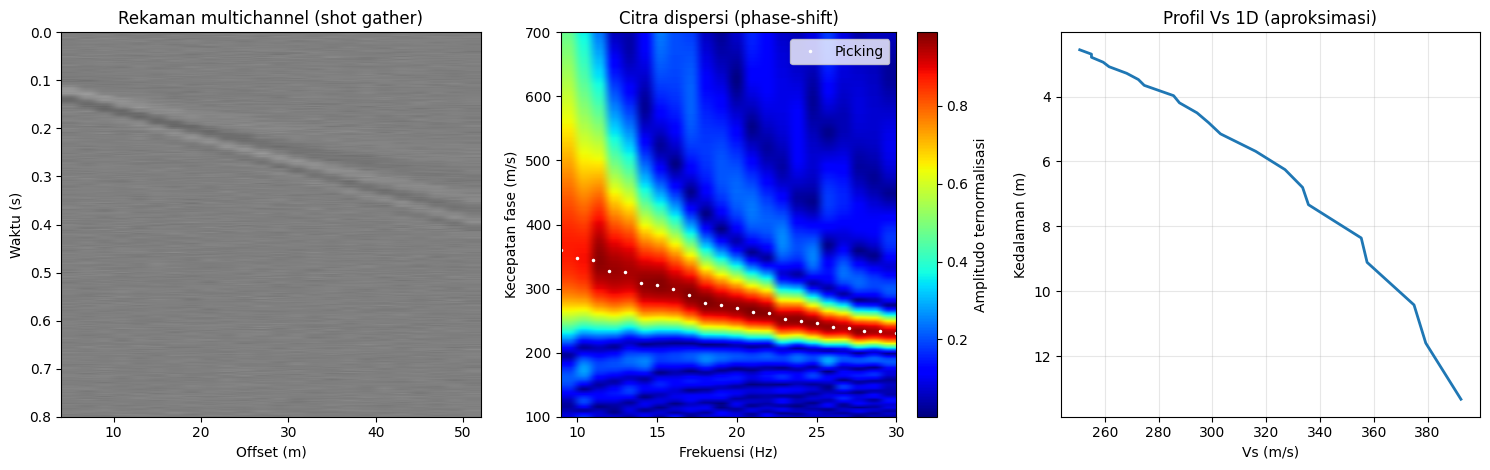

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. AKUISISI SINTETIS: 24 GEOPHONE, SPASI 2 M, OFFSET AWAL 5 M
# ============================================================
rng = np.random.default_rng(5)
dx, n_ch, x0 = 2.0, 24, 5.0
x = x0 + dx*np.arange(n_ch)
dt, nt = 0.002, 500
t = np.arange(nt)*dt
f = np.fft.rfftfreq(nt, dt)

# Kurva dispersi "benar" (kecepatan fase Rayleigh menurun terhadap frekuensi)
c_true = 190 + 330*np.exp(-f/14)

# Spektrum sumber (mirip Ricker, puncak ~20 Hz) dan rambatan dispersif + redaman
A = (f**2)*np.exp(-(f/20)**2); A /= A.max()
D = np.zeros((len(f), n_ch), dtype=complex)
for k, xi in enumerate(x):
    D[:, k] = A*np.exp(-2j*np.pi*f*(xi/c_true + 0.10))*np.exp(-0.01*xi)
gather = np.fft.irfft(D, n=nt, axis=0)
gather += 0.01*rng.normal(size=gather.shape)             # noise acak

# ============================================================
# 2. TRANSFORMASI PHASE-SHIFT -> CITRA DISPERSI (f - c)
# ============================================================
Dn = np.fft.rfft(gather, axis=0)
c_scan = np.arange(100, 701, 2.0)
fmin, fmax = 9, 30
fi = np.where((f >= fmin) & (f <= fmax))[0]
spec = np.zeros((len(c_scan), len(fi)))
for j, idx in enumerate(fi):
    u = Dn[idx, :]/(np.abs(Dn[idx, :]) + 1e-12)           # normalisasi amplitudo
    for m, c in enumerate(c_scan):
        spec[m, j] = np.abs(np.sum(u*np.exp(2j*np.pi*f[idx]*x/c)))/n_ch

# ============================================================
# 3. PICKING KURVA DISPERSI DAN KONVERSI KE PROFIL Vs 1D
# ============================================================
f_pick = f[fi]
c_pick = c_scan[np.argmax(spec, axis=0)]
from scipy.ndimage import median_filter
c_pick = median_filter(c_pick, size=3, mode='nearest')   # haluskan picking yang menyimpang
vs_pick = 1.09*c_pick                                     # aproksimasi Vs ~ 1,09 x Vr
depth_pick = (c_pick/f_pick)/3.0                          # kedalaman ~ panjang gelombang / 3
urut = np.argsort(depth_pick)

batas = [0, 3, 6, 10, 15, 30]
print("MASW - DATA SINTETIS (24 geophone, spasi 2 m, panjang bentangan 46 m)")
print(f"Rentang frekuensi terpakai   : {f_pick.min():.0f}-{f_pick.max():.0f} Hz")
print(f"Rentang kecepatan fase       : {c_pick.min():.0f}-{c_pick.max():.0f} m/s")
print(f"Rentang Vs hasil aproksimasi : {vs_pick.min():.0f}-{vs_pick.max():.0f} m/s")
print(f"Kedalaman investigasi efektif: {depth_pick.min():.1f}-{depth_pick.max():.1f} m\n")
print("Rata-rata Vs per interval kedalaman:")
for a, b in zip(batas[:-1], batas[1:]):
    m = (depth_pick >= a) & (depth_pick < b)
    if m.any():
        print(f"  {a:2d}-{b:2d} m : Vs rata-rata {vs_pick[m].mean():5.0f} m/s  ({m.sum()} titik)")
d_max = depth_pick.max()
dd = np.diff(np.r_[0, depth_pick[urut]])
vs_avg = d_max/np.sum(dd/vs_pick[urut])
print(f"\nVs rata-rata (harmonik) sampai {d_max:.1f} m : {vs_avg:.0f} m/s")
print("Catatan: ini aproksimasi cepat (bukan inversi penuh); data dibuat untuk demonstrasi.")

# ============================================================
# 4. VISUALISASI
# ============================================================
fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
ax[0].imshow(gather, aspect="auto", cmap="gray", extent=[x.min()-dx/2, x.max()+dx/2, t[-1], 0],
             vmin=-0.4, vmax=0.4)
ax[0].set_xlabel("Offset (m)"); ax[0].set_ylabel("Waktu (s)"); ax[0].set_ylim(0.8, 0)
ax[0].set_title("Rekaman multichannel (shot gather)")

im = ax[1].imshow(spec, aspect="auto", origin="lower", cmap="jet",
                  extent=[f_pick.min(), f_pick.max(), c_scan.min(), c_scan.max()])
ax[1].plot(f_pick, c_pick, "w.", ms=3, label="Picking")
ax[1].set_xlabel("Frekuensi (Hz)"); ax[1].set_ylabel("Kecepatan fase (m/s)")
ax[1].set_title("Citra dispersi (phase-shift)"); ax[1].legend(loc="upper right")
fig.colorbar(im, ax=ax[1], label="Amplitudo ternormalisasi")

ax[2].plot(vs_pick[urut], depth_pick[urut], lw=2)
ax[2].invert_yaxis(); ax[2].grid(True, alpha=0.3)
ax[2].set_xlabel("Vs (m/s)"); ax[2].set_ylabel("Kedalaman (m)"); ax[2].set_title("Profil Vs 1D (aproksimasi)")
plt.tight_layout(); plt.show()

**Interpretasi hasil:** Rekaman multichannel menghasilkan citra dispersi dengan energi yang terkonsentrasi pada satu pita jelas. Kecepatan fase pada pita tersebut menurun dari sekitar 360 m/s pada frekuensi rendah (sekitar 9 Hz) menjadi sekitar 230 m/s pada frekuensi yang lebih tinggi (sekitar 30 Hz). Pola ini adalah dispersi normal, yaitu komponen frekuensi rendah merambat lebih cepat karena merasakan lapisan yang lebih dalam dan lebih kaku, sedangkan komponen frekuensi tinggi hanya merasakan lapisan dangkal yang lebih lunak. Kurva dispersi yang halus tanpa lonjakan menunjukkan bahwa moda dasar gelombang Rayleigh dapat dibaca dengan baik pada data contoh ini.

Setelah kurva hasil picking dikonversi secara aproksimasi, kecepatan gelombang geser berkisar dari sekitar 250 m/s pada kedalaman dangkal hingga sekitar 390 m/s pada kedalaman sekitar 13 m. Rata-rata Vs per interval kedalaman naik dari sekitar 255 m/s pada kedalaman kurang dari 3 m, menjadi sekitar 290 m/s pada 3 sampai 6 m, sekitar 340 m/s pada 6 sampai 10 m, dan sekitar 380 m/s pada 10 sampai 13 m. Kenaikan yang bertahap ini menunjukkan material yang makin kompak dan kaku terhadap kedalaman, tanpa batas lapisan yang tegas. Nilai Vs sekitar 250 sampai 290 m/s di bagian atas sesuai dengan tanah berkonsistensi sedang hingga padat, sedangkan nilai 340 sampai 400 m/s di bagian bawah mengarah ke tanah keras atau transisi menuju batuan lapuk. Vs rata-rata harmonik sampai kedalaman sekitar 13,3 m adalah sekitar 317 m/s. Nilai ini belum dapat disebut Vs30 karena kedalaman yang terjangkau belum mencapai 30 m.

Hasil ini perlu dibaca dengan hati-hati. Kedalaman diperkirakan dari sepertiga panjang gelombang, sehingga profil yang diperoleh adalah gambaran kasar dan bukan hasil inversi penuh yang memperhitungkan struktur berlapis. Selain itu, frekuensi tertinggi yang dipakai membatasi resolusi lapisan paling dangkal sehingga bagian sekitar 2,6 m teratas tidak terwakili. Dalam praktik, profil ini perlu diperhalus melalui inversi kurva dispersi dan dibandingkan dengan data bor atau uji geoteknik sebelum dipakai untuk klasifikasi situs atau perancangan.

---

### PROMPT PENYELESAIAN STUDI KASUS GEOFISIKA MENGGUNAKAN METODE GROUND PENETRATING RADAR (GPR)

Role (R)

Anda adalah seorang ahli geofisika dengan spesialisasi metode Ground Penetrating Radar (GPR), berpengalaman dalam akuisisi dan pengolahan data radar penembus tanah, interpretasi reflektor bawah permukaan, serta penyusunan laporan teknis yang jelas dan sistematis.

Task (T)

Selesaikan studi kasus geofisika menggunakan metode GPR. Lakukan analisis lengkap mulai dari pemahaman data, pengolahan radargram, interpretasi struktur dan objek bawah permukaan, hingga penarikan kesimpulan, kemudian sampaikan seluruh hasilnya hanya dalam bentuk narasi.

Context (C)

Studi kasus ini menggunakan metode Ground Penetrating Radar untuk memperoleh informasi struktur dan objek bawah permukaan dangkal berdasarkan refleksi gelombang elektromagnetik. Hasil akhir harus dapat dipahami oleh pembaca teknis maupun semi-teknis tanpa menyajikan tabel, grafik, atau format terstruktur lainnya.

Input (I)

[Sisipkan di sini data atau deskripsi studi kasus yang Anda miliki, misalnya: data radargram, frekuensi antena, parameter akuisisi, atau hasil interpretasi reflektor. Jika belum tersedia, tuliskan “Data studi kasus akan diberikan kemudian.”]

Constraints (K)

1. Gunakan hanya metode GPR.
2. Jangan menyajikan output dalam bentuk tabel, daftar bernomor, bullet point, persamaan matematis terpisah, atau diagram.
3. Seluruh penjelasan harus mengalir dalam bentuk paragraf naratif yang koheren.
4. Fokus pada proses analisis, interpretasi geologi/geofisika, dan kesimpulan praktis.
5. Hindari spekulasi di luar data yang diberikan.

Output (O)

Sampaikan hasil penyelesaian studi kasus sepenuhnya dalam bentuk narasi mengalir. Narasi harus mencakup: ringkasan pendekatan yang digunakan, langkah-langkah analisis yang dilakukan, interpretasi struktur dan objek bawah permukaan yang diperoleh dari data GPR, serta kesimpulan dan implikasi praktis dari hasil tersebut. Tidak boleh ada format lain selain paragraf naratif.

---

## Eksekusi 4: Ground Penetrating Radar (GPR)

**Data sintetis:** radargram lintasan 0-20 m dengan jendela waktu 0-150 ns dan antena 250 MHz. Model berisi tiga reflektor berlapis (salah satunya sedikit miring), satu pola hiperbola dari objek terkubur di sekitar jarak 12 m, atenuasi, dan noise. Data dibuat untuk demonstrasi, bukan data lapangan.

**Tujuan eksekusi:** memperlihatkan pemrosesan dasar radargram (dewow, penghapusan gelombang langsung, gain), estimasi kecepatan dari hiperbola difraksi, dan konversi waktu tempuh ke kedalaman.

GPR - DATA SINTETIS (antena 250 MHz, lintasan 20 m, jendela waktu 150 ns)
Posisi puncak hiperbola     : x ~ 11.9 m, t0 ~ 20.5 ns
Kecepatan hasil fitting     : 0.102 m/ns -> permitivitas relatif ~ 8.6
Kedalaman objek (puncak)    : ~ 1.05 m
Reflektor datar t =  50 ns  : kedalaman ~ 2.55 m
Reflektor datar t =  80 ns  : kedalaman ~ 4.08 m
Reflektor datar t = 130 ns  : kedalaman ~ 6.63 m
Catatan: radargram merupakan simulasi untuk demonstrasi, bukan data lapangan.


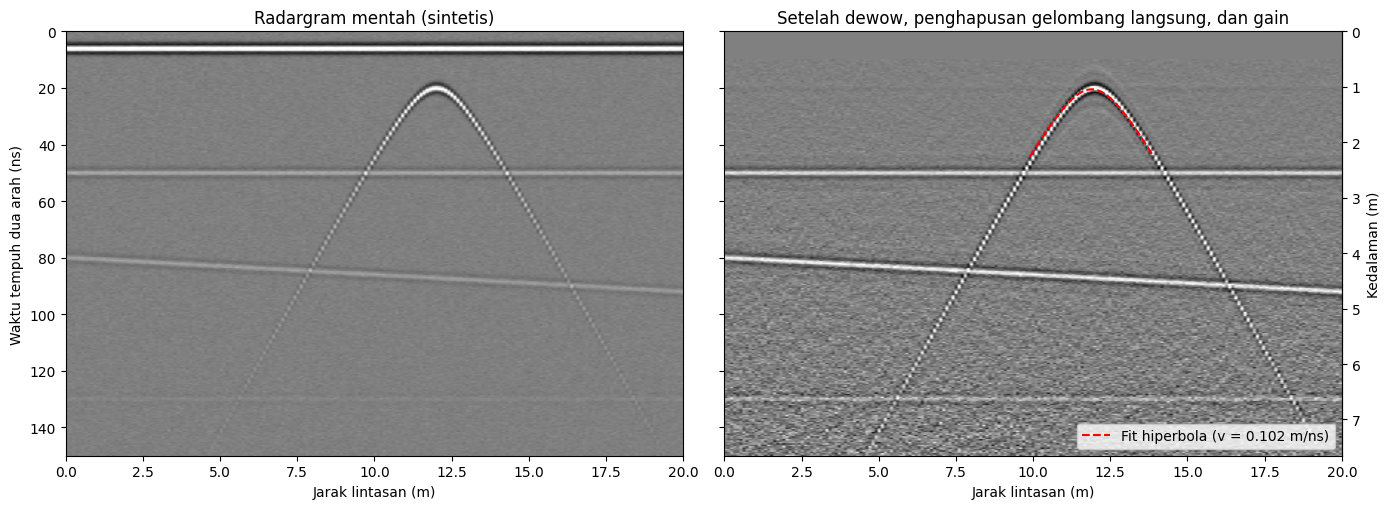

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PEMODELAN RADARGRAM SINTETIS (antena 250 MHz, lintasan 0-20 m, jendela 0-150 ns)
# ============================================================
rng = np.random.default_rng(21)
x = np.linspace(0, 20, 201)
t = np.linspace(0, 150, 301)                      # waktu tempuh dua arah (ns)
X, T = np.meshgrid(x, t)
v_true = 0.10                                     # m/ns (permitivitas relatif ~ 9), hanya untuk membangkitkan data
f0 = 0.25                                         # GHz

def ricker(tau):
    a = (np.pi*f0*tau)**2
    return (1 - 2*a)*np.exp(-a)

radar = 0.9*ricker(T - 6)                         # gelombang langsung (pita horizontal)
for z0, amp, dip in [(2.5, 0.50, 0.0), (4.0, 0.80, 0.03), (6.5, 0.45, 0.0)]:   # batas lapisan
    radar += amp*ricker(T - 2*(z0 + dip*x)/v_true)
x_p, z_p = 12.0, 1.0                              # objek terkubur (mis. pipa) pada x = 12 m, z = 1 m
t_hip = 2*np.sqrt(z_p**2 + (X - x_p)**2)/v_true
radar += 1.0*ricker(T - t_hip)
radar *= np.exp(-T/45)                            # atenuasi
radar += 0.015*rng.normal(size=radar.shape)       # noise

# ============================================================
# 2. PEMROSESAN SEDERHANA: dewow -> hapus gelombang langsung -> gain
# ============================================================
def dewow(a, w=25):
    k = np.ones(w)/w
    return a - np.apply_along_axis(lambda s: np.convolve(s, k, mode="same"), 0, a)

proc = dewow(radar)
proc = proc - np.where(T < 25, proc.mean(axis=1, keepdims=True), 0)   # hapus gelombang langsung (hanya zona awal agar reflektor datar tidak ikut hilang)
proc = proc*np.exp(T/70)                          # gain kompensasi atenuasi
proc[T < 10] = 0                                  # mute gelombang langsung

# ============================================================
# 3. ESTIMASI KECEPATAN DARI HIPERBOLA: t^2 = t0^2 + (2/v)^2 (x - xp)^2
# ============================================================
sel = (abs(x - x_p) <= 2.0)
t_pick, x_pick = [], []
for i in np.where(sel)[0]:
    w = (t > 12) & (t < 46)
    t_pick.append(t[w][np.argmax(proc[w, i])]); x_pick.append(x[i])
t_pick, x_pick = np.array(t_pick), np.array(x_pick)
x_apex = x_pick[np.argmin(t_pick)]
slope, interc = np.polyfit((x_pick - x_apex)**2, t_pick**2, 1)
v_est = 2/np.sqrt(slope)
t0 = np.sqrt(interc)
z_obj = v_est*t0/2
eps_r = (0.2998/v_est)**2

print("GPR - DATA SINTETIS (antena 250 MHz, lintasan 20 m, jendela waktu 150 ns)")
print(f"Posisi puncak hiperbola     : x ~ {x_apex:.1f} m, t0 ~ {t0:.1f} ns")
print(f"Kecepatan hasil fitting     : {v_est:.3f} m/ns -> permitivitas relatif ~ {eps_r:.1f}")
print(f"Kedalaman objek (puncak)    : ~ {z_obj:.2f} m")
for tt in (50, 80, 130):
    print(f"Reflektor datar t = {tt:3d} ns  : kedalaman ~ {v_est*tt/2:.2f} m")
print("Catatan: radargram merupakan simulasi untuk demonstrasi, bukan data lapangan.")

# ============================================================
# 4. VISUALISASI
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
ax[0].imshow(radar, extent=[0, 20, t.max(), 0], aspect="auto", cmap="gray", vmin=-0.5, vmax=0.5)
ax[0].set_title("Radargram mentah (sintetis)")
ax[1].imshow(proc, extent=[0, 20, t.max(), 0], aspect="auto", cmap="gray", vmin=-0.45, vmax=0.45)
xx = np.linspace(x_apex-2, x_apex+2, 100)
ax[1].plot(xx, np.sqrt(t0**2 + slope*(xx-x_apex)**2), "r--", lw=1.5, label=f"Fit hiperbola (v = {v_est:.3f} m/ns)")
ax[1].set_title("Setelah dewow, penghapusan gelombang langsung, dan gain"); ax[1].legend(loc="lower right")
for a in ax: a.set_xlabel("Jarak lintasan (m)")
ax[0].set_ylabel("Waktu tempuh dua arah (ns)")
sec = ax[1].secondary_yaxis("right", functions=(lambda tt: tt*v_est/2, lambda zz: zz*2/v_est))
sec.set_ylabel("Kedalaman (m)")
plt.tight_layout(); plt.show()

**Interpretasi hasil:** Radargram mentah didominasi oleh pita horizontal kuat di bagian atas yang berasal dari gelombang langsung dan oleh amplitudo yang cepat melemah terhadap waktu. Setelah dewow, penghapusan gelombang langsung, dan gain, reflektor di bagian lebih dalam muncul dengan jelas. Terlihat tiga reflektor yang relatif menerus pada waktu sekitar 50, 80, dan 130 ns, serta satu pola hiperbola dengan puncak di sekitar jarak 12 m pada waktu sekitar 20 ns. Reflektor pada 80 ns terlihat sedikit miring sepanjang lintasan dan memiliki amplitudo paling kuat, yang menandakan kontras sifat elektromagnetik paling besar di antara ketiganya.

Kecepatan gelombang diestimasi dari kelengkungan hiperbola dan diperoleh sekitar 0,10 m/ns. Nilai ini setara dengan permitivitas relatif sekitar 8 sampai 9, yang sesuai dengan tanah berpasir yang lembap. Dengan kecepatan tersebut, puncak hiperbola berada pada kedalaman sekitar 1,05 m. Pola hiperbola terbentuk dari difraksi pada objek kecil yang terlokalisasi, seperti pipa, kabel, atau bongkah, tetapi jenis objeknya tidak dapat dipastikan hanya dari radargram. Tiga reflektor datar masing-masing berada pada kedalaman sekitar 2,5 m, 4,1 m, dan 6,6 m. Reflektor pertama dapat berkaitan dengan perubahan material atau tekstur tanah. Reflektor kedua yang kuat dan sedikit miring dapat menunjukkan batas dengan kontras kadar air besar, misalnya muka air tanah. Reflektor ketiga yang lebih lemah dapat berkaitan dengan batas material yang lebih dalam, misalnya batuan dasar atau lapisan padat.

Secara praktis, data ini menunjukkan bahwa objek terkubur pada kedalaman sekitar 1 m di jarak 12 m layak diverifikasi, misalnya dengan penggalian terbatas, dan bahwa struktur dangkal di lokasi ini berlapis dengan sedikit kemiringan. Kedalaman yang dihitung bergantung pada kecepatan hasil fitting, sehingga akurasinya perlu dikalibrasi dengan data penggalian atau bor sebelum dijadikan dasar keputusan. Pada kondisi lapangan nyata, kedalaman penetrasi juga bisa jauh lebih kecil jika tanah bersifat sangat konduktif, misalnya tanah lempung.

### PROMPT PENYELESAIAN STUDI KASUS GEOFISIKA MENGGUNAKAN METODE INDUCED POLARIZATION (IP)

Role (R)

Anda adalah seorang ahli geofisika dengan spesialisasi metode Induced Polarization (IP), berpengalaman dalam akuisisi dan pengolahan data polarisasi terinduksi, interpretasi chargeability dan resistivitas, serta penyusunan laporan teknis yang jelas dan sistematis.

Task (T)

Selesaikan studi kasus geofisika menggunakan metode Induced Polarization (IP). Lakukan analisis lengkap mulai dari pemahaman data, pengolahan, interpretasi anomali chargeability dan resistivitas, hingga penarikan kesimpulan, kemudian sampaikan seluruh hasilnya hanya dalam bentuk narasi.

Context (C)

Studi kasus ini menggunakan metode Induced Polarization untuk memperoleh informasi struktur bawah permukaan berdasarkan distribusi chargeability dan resistivitas. Hasil akhir harus dapat dipahami oleh pembaca teknis maupun semi-teknis tanpa menyajikan tabel, grafik, atau format terstruktur lainnya.

Input (I)

[Sisipkan di sini data atau deskripsi studi kasus yang Anda miliki, misalnya: data chargeability, resistivitas semu, parameter akuisisi, atau hasil inversi. Jika belum tersedia, tuliskan “Data studi kasus akan diberikan kemudian.”]

Constraints (K)

1. Gunakan hanya metode Induced Polarization (IP).
2. Jangan menyajikan output dalam bentuk tabel, daftar bernomor, bullet point, persamaan matematis terpisah, atau diagram.
3. Seluruh penjelasan harus mengalir dalam bentuk paragraf naratif yang koheren.
4. Fokus pada proses analisis, interpretasi geologi/geofisika, dan kesimpulan praktis.
5. Hindari spekulasi di luar data yang diberikan.

Output (O)

Sampaikan hasil penyelesaian studi kasus sepenuhnya dalam bentuk narasi mengalir. Narasi harus mencakup: ringkasan pendekatan yang digunakan, langkah-langkah analisis yang dilakukan, interpretasi struktur bawah permukaan yang diperoleh dari data chargeability dan resistivitas, serta kesimpulan dan implikasi praktis dari hasil tersebut. Tidak boleh ada format lain selain paragraf naratif.

## Eksekusi 5: Induced Polarization (IP)

**Data sintetis:** penampang resistivitas dan chargeability hasil survei dipole-dipole sepanjang 200 m dengan kedalaman model 50 m. Model berisi tubuh mineralisasi sulfida tersebar (chargeability tinggi, resistivitas rendah), lapisan lempung dangkal di bagian kiri (resistivitas sangat rendah, chargeability rendah hingga sedang), dan zona batuan segar atau silisifikasi di bagian kanan (resistivitas sangat tinggi, chargeability rendah). Data dibuat untuk demonstrasi, bukan hasil survei lapangan.

**Tujuan eksekusi:** menunjukkan bahwa anomali IP harus dibaca bersama resistivitas, karena kombinasi keduanya dapat membedakan zona yang sama-sama tampak anomali pada salah satu penampang saja.

IP - DATA SINTETIS (dipole-dipole, lintasan 200 m, kedalaman model 50 m)
Resistivitas  : 13.3-835 ohm.m (latar belakang sekitar 80-180 ohm.m)
Chargeability : 2.7-31.3 mV/V (latar belakang sekitar 3-4 mV/V)

Anomali IP tinggi + resistivitas rendah    x =  99.0-140.0 m, kedalaman 11.5-33.0 m, rho median   82.1 ohm.m, M median  18.4 mV/V
Resistivitas rendah + IP rendah            x =  10.0- 59.0 m, kedalaman  1.0-10.0 m, rho median   35.1 ohm.m, M median   5.3 mV/V
Resistivitas tinggi + IP rendah            x = 142.0-200.0 m, kedalaman 12.0-46.0 m, rho median  410.5 ohm.m, M median   3.7 mV/V
Catatan: nilai dibuat untuk demonstrasi, bukan hasil survei lapangan.


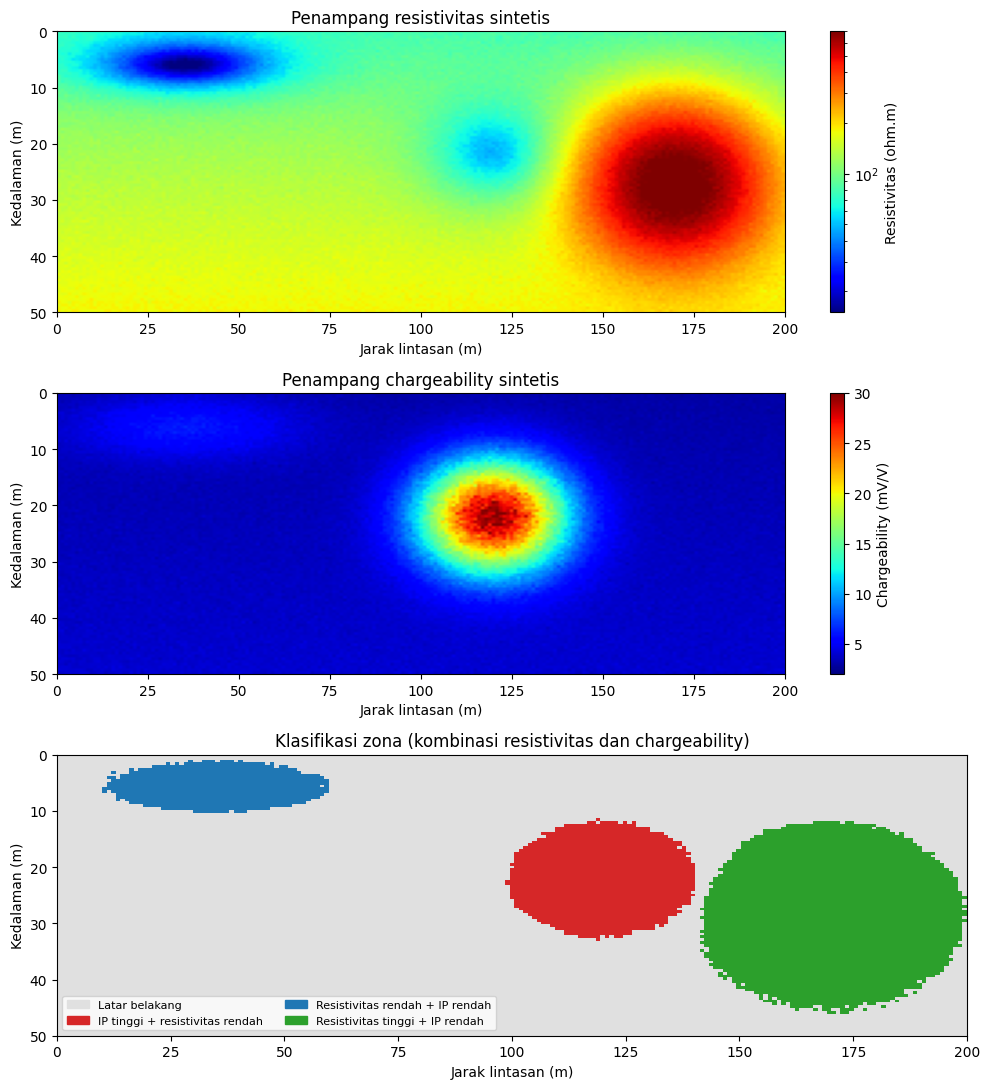

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, ListedColormap
from matplotlib.patches import Patch

# ============================================================
# 1. MODEL SINTETIS RESISTIVITAS & CHARGEABILITY (hasil inversi simulasi)
#    Dipole-dipole, lintasan 200 m, kedalaman model 50 m
# ============================================================
x = np.linspace(0, 200, 201)
z = np.linspace(0, 50, 101)
X, Z = np.meshgrid(x, z)
g = lambda xc, zc, sx, sz: np.exp(-(((X-xc)/sx)**2 + ((Z-zc)/sz)**2)/2)

rng = np.random.default_rng(9)
rho = 80 + 2.0*Z                                               # latar belakang (ohm.m)
M   = 3.0 + 0.02*Z                                             # latar belakang (mV/V)

b_sulfida = g(120, 22, 14, 7)      # tubuh mineralisasi sulfida tersebar : resistivitas rendah, chargeability tinggi
b_lempung = g(35, 6, 22, 4)        # lapisan lempung dangkal            : resistivitas sangat rendah, chargeability rendah-sedang
b_silika  = g(170, 26, 16, 9)      # zona silisifikasi / batuan segar   : resistivitas sangat tinggi, chargeability rendah

rho = rho*(1 - 0.62*b_sulfida)*(1 - 0.85*b_lempung)*(1 + 5.0*b_silika)
M   = M + 26*b_sulfida + 3*b_lempung + 4*b_silika*0
rho *= np.exp(0.03*rng.normal(size=rho.shape))
M   *= (1 + 0.04*rng.normal(size=M.shape))

# ============================================================
# 2. KLASIFIKASI ZONA BERDASARKAN KOMBINASI RESISTIVITAS & CHARGEABILITY
# ============================================================
rho_rendah, rho_tinggi, M_tinggi = 50, 250, 12
kelas = np.zeros(rho.shape, dtype=int)                         # 0 = latar belakang
kelas[(M >= M_tinggi) & (rho < rho_tinggi)] = 1                # M tinggi, rho rendah-sedang -> sulfida tersebar
kelas[(M < M_tinggi) & (rho < rho_rendah)]  = 2                # M rendah, rho rendah       -> lempung / air asin
kelas[(M < M_tinggi) & (rho >= rho_tinggi)] = 3                # M rendah, rho tinggi       -> batuan segar / silika

print("IP - DATA SINTETIS (dipole-dipole, lintasan 200 m, kedalaman model 50 m)")
print(f"Resistivitas  : {rho.min():.1f}-{rho.max():.0f} ohm.m (latar belakang sekitar 80-180 ohm.m)")
print(f"Chargeability : {M.min():.1f}-{M.max():.1f} mV/V (latar belakang sekitar 3-4 mV/V)\n")
nama = {1: "Anomali IP tinggi + resistivitas rendah", 2: "Resistivitas rendah + IP rendah",
        3: "Resistivitas tinggi + IP rendah"}
for k in (1, 2, 3):
    m = kelas == k
    if m.any():
        xs, zs = X[m], Z[m]
        print(f"{nama[k]:42s} x = {xs.min():5.1f}-{xs.max():5.1f} m, kedalaman {zs.min():4.1f}-{zs.max():4.1f} m, "
              f"rho median {np.median(rho[m]):6.1f} ohm.m, M median {np.median(M[m]):5.1f} mV/V")
print("Catatan: nilai dibuat untuk demonstrasi, bukan hasil survei lapangan.")

# ============================================================
# 3. VISUALISASI
# ============================================================
fig, ax = plt.subplots(3, 1, figsize=(10, 11))
im0 = ax[0].imshow(rho, extent=[0, 200, 50, 0], aspect="auto", cmap="jet", norm=LogNorm(vmin=15, vmax=700))
fig.colorbar(im0, ax=ax[0], label="Resistivitas (ohm.m)"); ax[0].set_title("Penampang resistivitas sintetis")
im1 = ax[1].imshow(M, extent=[0, 200, 50, 0], aspect="auto", cmap="jet", vmin=2, vmax=30)
fig.colorbar(im1, ax=ax[1], label="Chargeability (mV/V)"); ax[1].set_title("Penampang chargeability sintetis")
cmap = ListedColormap(["#e0e0e0", "#d62728", "#1f77b4", "#2ca02c"])
ax[2].imshow(kelas, extent=[0, 200, 50, 0], aspect="auto", cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
ax[2].set_title("Klasifikasi zona (kombinasi resistivitas dan chargeability)")
ax[2].legend(handles=[Patch(color="#e0e0e0", label="Latar belakang"),
                      Patch(color="#d62728", label="IP tinggi + resistivitas rendah"),
                      Patch(color="#1f77b4", label="Resistivitas rendah + IP rendah"),
                      Patch(color="#2ca02c", label="Resistivitas tinggi + IP rendah")],
             loc="lower left", fontsize=8, ncol=2)
for a in ax: a.set_xlabel("Jarak lintasan (m)"); a.set_ylabel("Kedalaman (m)")
plt.tight_layout(); plt.show()

**Interpretasi hasil:** Penampang chargeability memperlihatkan latar belakang yang rendah, sekitar 3 sampai 4 mV/V, dengan satu anomali tinggi yang jelas di sekitar jarak 99 sampai 140 m pada kedalaman sekitar 11 sampai 33 m. Nilai chargeability di zona tersebut mencapai sekitar 18 mV/V (median) dengan nilai maksimum lebih dari 30 mV/V. Pada penampang resistivitas, zona yang sama bernilai rendah sampai sedang, yaitu sekitar 80 ohm.m (median), lebih rendah dari latar belakang pada kedalaman yang sama. Kombinasi chargeability tinggi dengan resistivitas rendah sampai sedang sesuai dengan mineralisasi sulfida tersebar, karena mineral logam yang menghantarkan listrik memperkuat efek polarisasi sekaligus menurunkan resistivitas batuan. Zona ini menjadi target utama untuk dikaji lebih lanjut.

Di bagian kiri lintasan, pada jarak sekitar 10 sampai 59 m dan kedalaman 1 sampai 10 m, terdapat zona beresistivitas sangat rendah sekitar 35 ohm.m. Chargeability di zona ini hanya sekitar 5 mV/V, jauh di bawah anomali sulfida. Kombinasi ini lebih sesuai dengan lempung atau material halus yang lembap daripada mineralisasi logam, sehingga zona ini sebaiknya tidak dianggap target walaupun resistivitasnya rendah. Di bagian kanan, pada jarak sekitar 142 sampai 200 m dan kedalaman 12 sampai 46 m, resistivitas sangat tinggi sekitar 410 ohm.m disertai chargeability rendah sekitar 3,7 mV/V. Pola ini sesuai dengan batuan yang kompak dan kering atau teralterasi silika yang hampir tidak terpolarisasi, sehingga tidak menunjukkan indikasi mineral logam.

Secara keseluruhan, pembacaan dua parameter secara bersamaan memisahkan tiga zona dengan karakter berbeda: zona sulfida potensial di bagian tengah, zona lempung dangkal di kiri, dan zona batuan resistif di kanan. Untuk tujuan eksplorasi, area sekitar jarak 120 m pada kedalaman sekitar 20 m layak diprioritaskan untuk survei detail atau pemboran uji. Namun, anomali IP tidak bersifat unik. Grafit, magnetit, atau lempung tertentu juga dapat menghasilkan chargeability tinggi, sehingga hasil ini perlu dikonfirmasi dengan geologi, pengambilan sampel, atau metode geofisika lain. Resolusi hasil inversi juga menurun terhadap kedalaman, sehingga batas bawah anomali kurang pasti dibandingkan batas atasnya.